# Trabajo Práctico 2: Aprendizaje No-Supervisado

## Parte 1: Inspección de Datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv("data/fashion_mnist_subset.csv")

## Descripción del dataset:
Se utiliza en este Trabajo Práctico el dataset "ashion_mnist_subset.csv", que contiene 25000 filas, y caa una es una imagen de una prenda de ropa en escala de grises. Cada imágen está en 28x28 píxeles. Las columnas "pixel_0" hasta la columna "pixel_783" contienen sus 784 valores de píxeles y la columna "label" indica la clase a la cual pertenece la prenda. El dataset contienen 10 clases, identificadas con etiquetas del 0 al 9. Se utilizan esas etiquetas para explorar la distribución de clases para así entender y utilizar de forma correcta el dataset. 

#### a) Se implementó una función que permite graficar un numero específico de imágenes del dataset en una grilla de cinco columnas. Cada imágen se reconstruye utilizando sus 784 píxeles en una matríz 28x28 y se ve en una escala de grises. Aquí mostramos un caso con 15 imágenes seleccionadas de forma aleatoria sin repetición, utilizando una semilla fija para repetir la selección: 

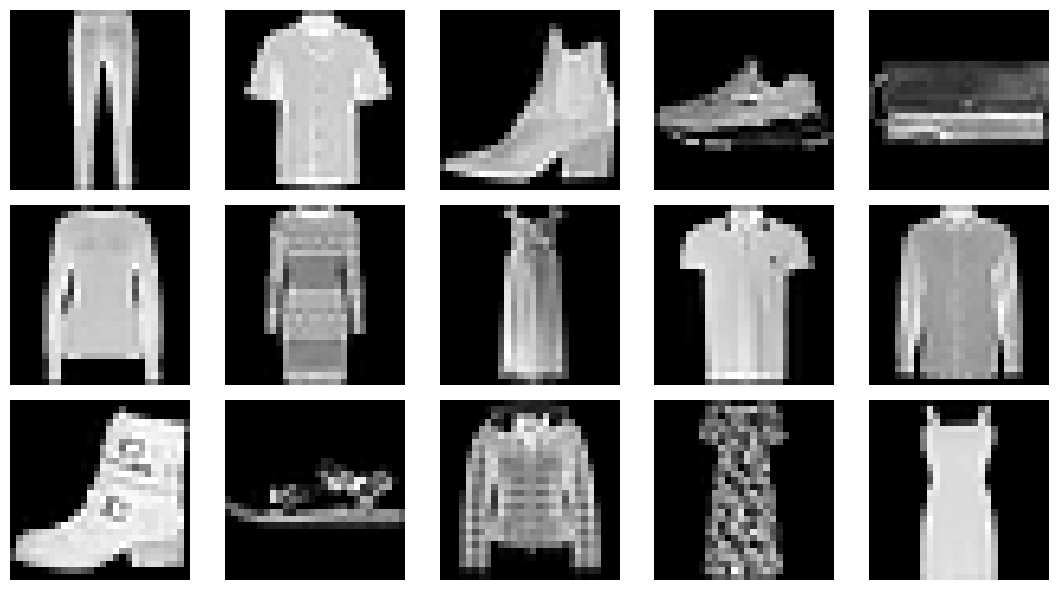

In [2]:
from src.graphing_imgs import graph_images
images = df.drop(columns="label").to_numpy()
generator = np.random.default_rng(60)
indxs = generator.choice(len(images), size=15, replace=False)
images_chosen = images[indxs]
graph_images(images_chosen)

### Hacemos un analisis exploratorio enfocado en la distribución de clases en los datos:

b) Se realizó un análisis exploratorio del set de datos enfocado en la distribución de clases en los datos. 

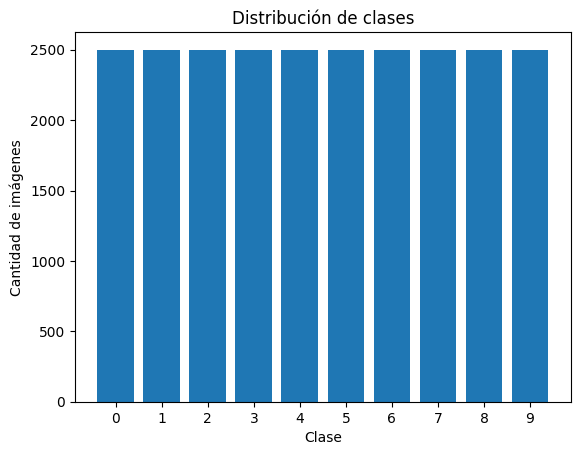

In [3]:
amounts = df["label"].value_counts().sort_index()
plt.bar(amounts.index, amounts.values)
plt.xlabel("Clase")
plt.ylabel("Cantidad de imágenes")
plt.title("Distribución de clases")
plt.xticks(amounts.index)
plt.show()

Las 10 clases están perfectamente balanceadas, con 2500 imágenes por clase. Cada clase representa 10% del total por lo cual la distribución de clases esta balanceada. 

Clase: 0


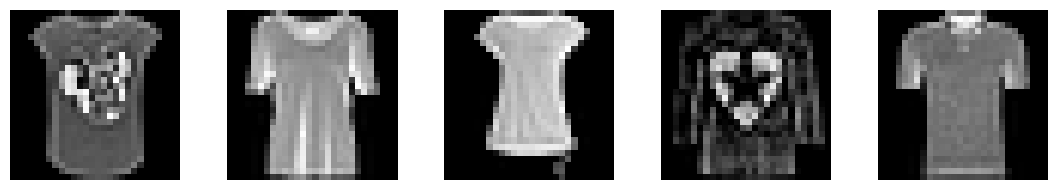

Clase: 1


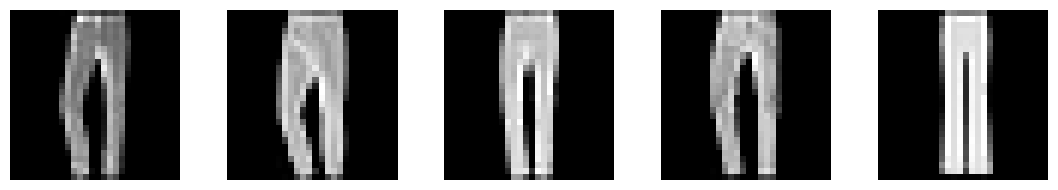

Clase: 2


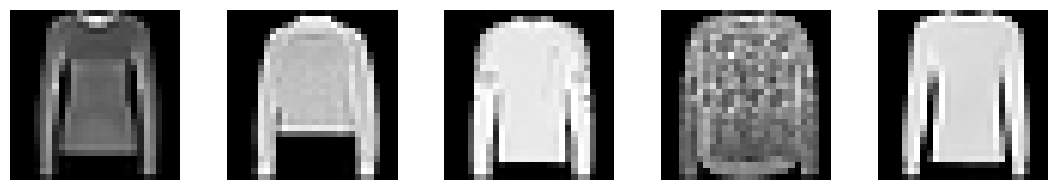

Clase: 3


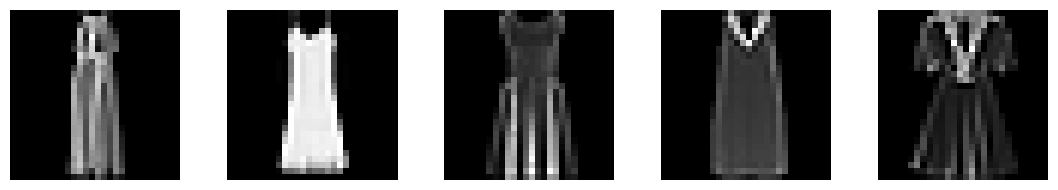

Clase: 4


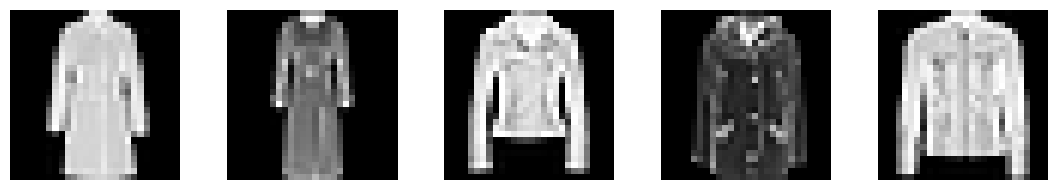

In [4]:
generator = np.random.default_rng(60)
for class_ in range(5):
    print("Clase:", class_)
    data_class = df[df["label"] == class_]
    images_class = data_class.drop(columns="label").to_numpy()
    indxs = generator.choice(len(images_class), size=5, replace=False)
    images_chosen = images_class[indxs]
    graph_images(images_chosen)

Al observar 5 imagenes aleatorias de 5 clases diferentes, es posible observar que aunque las clases estén balanceadas, las imágenes presentan variaciones de forma, intensidad y detalles en cada prenda. Se observan, asimismo, similitudes entre algunas clases, por ejemplo entre las clases 2 y 3, se ven prendas de manga larga. Estas similitudes van a dificultar la separación utilizando solamente información de los píxeles. 

#### c) Se realizó un split de datos estratificado, que respeta las proporciones de clases en cada split. Se dividió el dataset en un 80% para el train que represento 20000 filas, y se preservó un 20%, unas 5000 imágenes, para el test. Aunque el dataset original está balanceado, la estratificación permite que se conserve este balance en la division de los conjuntos. Por lo tanto, se verificó que cada clase tiene 2000 imágenes en el conjunto de entrenamiento, y 500 en el de evaluación, manteniendo la proporción del 10% de cada clase. 

In [5]:
from src.stratified_split import stratified_split
labels = df["label"].to_numpy()
train_indxs, test_indxs = stratified_split(labels)
X_train = images[train_indxs]
X_test = images[test_indxs]
y_train = labels[train_indxs]
y_test = labels[test_indxs]

print("Imagenes para train:", len(X_train))
print("Imagenes para test:", len(X_test))

#Para ver si mantiene proporciones de clases:
print("Train por clase:")
print(pd.Series(y_train).value_counts().sort_index())
print("Test por clase:")
print(pd.Series(y_test).value_counts().sort_index())


Imagenes para train: 20000
Imagenes para test: 5000
Train por clase:
0    2000
1    2000
2    2000
3    2000
4    2000
5    2000
6    2000
7    2000
8    2000
9    2000
Name: count, dtype: int64
Test por clase:
0    500
1    500
2    500
3    500
4    500
5    500
6    500
7    500
8    500
9    500
Name: count, dtype: int64


## Parte 2: Reducción de Dimensionalidad

#### a) Se implementó una estandarización de los datos y se implementó Principal Component Analysis. Para la estandarización, se calculó la media y el desvío estándar de cada píxel del conjunto de entrenamiento. Se utilizaron luego estos datos para transformar tanto el conjunto de entrenamiento como el conjunto de evaluación: se les restó la media a los datos de cada píxel y se dividieron por el desvío estándar. Esto evita que los píxeles de mayor varianza dominen el análisis. 

#### Luego, para implementar PCA, se calculó la matriz de covarianza de los datos de entrenamiento centrados y se obtuvieron sus autovalores y autovectores. Estos autovalores se ordenaron de mayor a menor junto con su autovector asociado para priorizar direcciones de mayor varianza. Así se aprenden las direcciones usando entrenamiento y se utilizan esas direcciones para reducir la dimensionalidad de todas las imágenes, tanto del train como el conjunto test. 

In [6]:
from src.standardization import standardization_fit, standardize
means, devs = standardization_fit(X_train)
X_train_std = standardize(X_train, means, devs)
X_test_std = standardize(X_test, means, devs)

In [58]:
from src.pca import pca_fit, pca
pca_mean, autovalores, autovectores = pca_fit(X_train_std)

/Users/ines/Desktop/MACHINE LEARNING/Mestres_Ines_TP4/Mestres_Ines_TP4/src/pca.py:7: RuntimeWarning: divide by zero encountered in matmul
  cov = (X_centered.T @ X_centered)/n
/Users/ines/Desktop/MACHINE LEARNING/Mestres_Ines_TP4/Mestres_Ines_TP4/src/pca.py:7: RuntimeWarning: overflow encountered in matmul
  cov = (X_centered.T @ X_centered)/n
/Users/ines/Desktop/MACHINE LEARNING/Mestres_Ines_TP4/Mestres_Ines_TP4/src/pca.py:7: RuntimeWarning: invalid value encountered in matmul
  cov = (X_centered.T @ X_centered)/n


#### b) Se realizó un gráfico que muestra la varianza explicada acumulada en función del número de componentes. Se calculó la proporción de varianza explicada por cada componente dividiendo su autovalor por la suma de todos los autovalores. Se acumularon estas proporciones para graficar esto. La línea roja indica el umbral del 90%. 

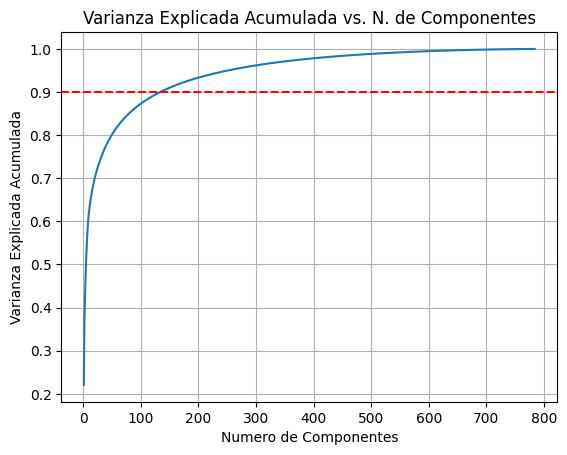

In [8]:
explained_variance_ratio = autovalores / np.sum(autovalores)
cumulative_variance = np.cumsum(explained_variance_ratio)
n_components = np.arange(1, len(autovalores) + 1)

plt.plot(n_components, cumulative_variance)
plt.axhline(y=0.90, color="red", linestyle="--")
plt.xlabel("Numero de Componentes")
plt.ylabel("Varianza Explicada Acumulada")
plt.title("Varianza Explicada Acumulada vs. N. de Componentes")
plt.grid(True)
plt.show()

In [12]:
n_components_90 = int(np.searchsorted(cumulative_variance, 0.90)) + 1
print("Componentes necesitados para explicar 90% de la varianza:", n_components_90)

Componentes necesitados para explicar 90% de la varianza: 134


#### Se conservaron 134 componentes, que es la cantidad mínima para explicar el 90% de la varianza de los datos de entrenamiento estandarizados. Cada imagen pasa de tener 784 características a 134. Observamos en el gráfico que los primeros componentes contienen la mayor parte de la varianza y los siguientes aportan cada vez menos información. 

#### Se seleccionaron cinco imágenes aleatorias del conjunto de evaluación. Para cada una, se obtuvo una representación de 134 componentes mediante PCA, y a partir de ella, se generó una reconstrucción de 784 píxeles. Luego, se deshizo la estandarización de as reconstrucciones para mostrarlas en la misma escala que las originales. Utilizando la función de la primer parte, se graficaron las imágenes originales en una primer fila y sus reconstrucciones en la segunda para poder compararlas. 

/Users/ines/Desktop/MACHINE LEARNING/Mestres_Ines_TP4/Mestres_Ines_TP4/src/pca.py:22: RuntimeWarning: divide by zero encountered in matmul
  X_reconstructed = Z @ components.T + mean
/Users/ines/Desktop/MACHINE LEARNING/Mestres_Ines_TP4/Mestres_Ines_TP4/src/pca.py:22: RuntimeWarning: overflow encountered in matmul
  X_reconstructed = Z @ components.T + mean
/Users/ines/Desktop/MACHINE LEARNING/Mestres_Ines_TP4/Mestres_Ines_TP4/src/pca.py:22: RuntimeWarning: invalid value encountered in matmul
  X_reconstructed = Z @ components.T + mean


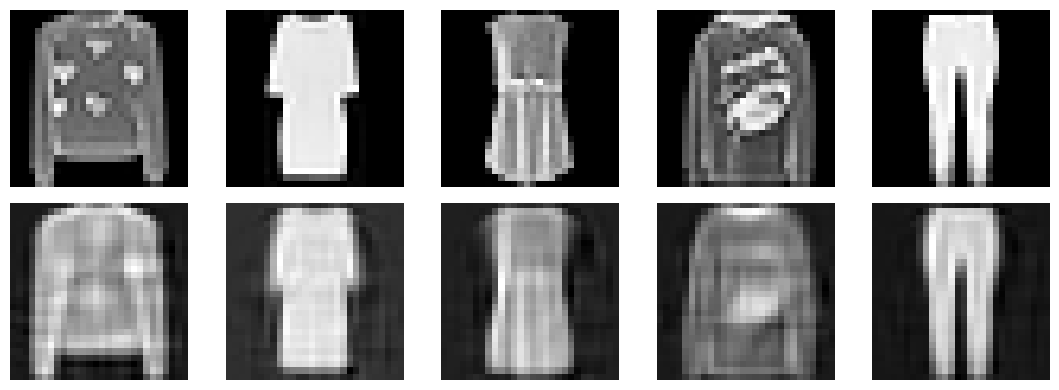

In [14]:
from src.pca import pca, reconstruction_pca
Z_train = pca(X_train_std, pca_mean, autovectores, n_components_90)
Z_test = pca(X_test_std, pca_mean, autovectores, n_components_90)
generator = np.random.default_rng(60)
indxs = generator.choice(len(X_test), size=5, replace=False)
original_images = X_test[indxs]
reduced_images = Z_test[indxs]
reconstructed_std = reconstruction_pca(reduced_images, pca_mean, autovectores, n_components_90)
reconstructed_images = reconstructed_std * devs + means
comparison_images = np.concatenate([original_images, reconstructed_images])
graph_images(comparison_images)

#### Las reconstrucciones conservan las silhuetas generales de las prendas, pero presentan bordes mas suaves y gran pérdida de detalles, por ejemplo, los estampados no se ven. Esto refleja la pérdida de información que resulta de descartar componentes y descubrimos que conservar al menos el 90% de la varianza no es equivalente a conservar 90% de la calidad visual de una imágen. 

#### c) Se entrenó un modelo autoencoder determinístico (AE) utilizando la librería Pytorch para entrenar la red neuronal del encoder y la del decoder. Se utilizó la misma dimensión latente obtenida en el PCA, que era 134, para permitir su comparación. Entonces, el encoder transforma 784 valores de cada imágen en una representación de 134 valores, utilizando una capa intermedia de 300 neuronas. El decoder realiza el recorrido de 134 a 300 y luego a 784 valores intentando reconstruir la imágen original. En las capas intermedias se utilizó la función de activación ReLU y en la final, Sigmoid porque los píxeles del dataset estan en el intervalo de 0 a 1. Para seleccionar los hiperparámetros, se separó de forma estratificada un 20% del conjunto de entrenamiento para la validación. Se utilizó el optimizador Adam y un tamaño de batch de 115. 

In [28]:
import torch
from torch.utils.data import DataLoader
from src.autoencoder import Autoencoder

X_train_AE = torch.tensor(X_train, dtype=torch.float32)
X_test_AE = torch.tensor(X_test, dtype=torch.float32)
fit_indxs, validation_indxs = stratified_split(y_train)
X_fit_AE = X_train_AE[fit_indxs]
X_validation_AE = X_train_AE[validation_indxs]

train_loader = DataLoader(X_fit_AE, batch_size=115, shuffle=True)
validation_loader = DataLoader(X_validation_AE, batch_size=115, shuffle=False)
loss_function = torch.nn.MSELoss()

In [41]:
import copy

def train_autoencoder(learning_rate, epochs):
    torch.manual_seed(60)
    model = Autoencoder(dim_final=n_components_90)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    train_losses = []
    validation_losses = []
    best_validation_loss = float("inf")
    best_epoch = 0
    best_weights = None
    for epoch in range(epochs):
        model.train()
        total_train_loss = 0
        for batch in train_loader:
            optimizer.zero_grad()
            reconstructed = model(batch)
            loss = loss_function(reconstructed, batch)
            loss.backward()
            optimizer.step()
            total_train_loss += loss.item()*len(batch)
        train_loss = total_train_loss/len(X_fit_AE)
        train_losses.append(train_loss)
        model.eval()
        total_validation_loss = 0
        with torch.no_grad():
            for batch in validation_loader:
                reconstructed = model(batch)
                loss = loss_function(reconstructed, batch)
                total_validation_loss += loss.item() * len(batch)
        validation_loss = total_validation_loss / len(X_validation_AE)
        validation_losses.append(validation_loss)
        if validation_loss < best_validation_loss:
            best_validation_loss = validation_loss
            best_epoch = epoch + 1
            best_weights = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_weights)
    model.eval()
    return model, train_losses, validation_losses, best_epoch, best_validation_loss


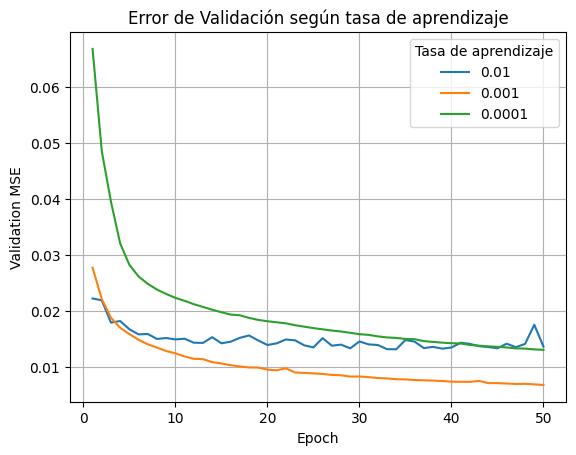

In [33]:
for learning_rate in results:
    losses = results[learning_rate]["validation_losses"]
    epoch_numbers = range(1, len(losses) + 1)

    plt.plot(epoch_numbers, losses, label=str(learning_rate))

plt.xlabel("Epoch")
plt.ylabel("Validation MSE")
plt.title("Error de Validación según tasa de aprendizaje")
plt.legend(title="Tasa de aprendizaje")
plt.grid(True)
plt.show()

#### Además, se compararon tres tasas de aprendizaje: 0.01, 0.001, y 0.0001 durante 50 epocas y se seleccionó 0.001 por obtener el menor error MSE de validación. 

#### Luego se probó aplificar el entrenamiento a 100 épocas con el learning rate seleccionado de 0.001 para evaluar si entrenar durante mas épocas mejoraba las reconstrucciones. Se graficaron los errores de entrenamiento y validación para observar su evolución y seleccionar la época con menor error de validación. 

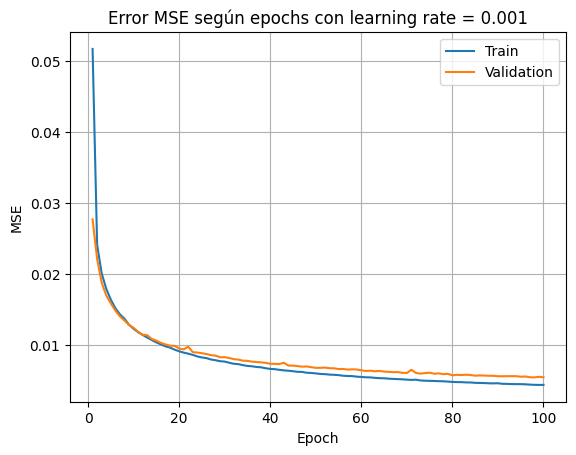

In [44]:
model_100, train_losses_100, validation_losses_100, best_epoch_100, best_loss_100 = (train_autoencoder(learning_rate=0.001, epochs=100))
epoch_numbers = range(1, len(train_losses_100) + 1)

plt.plot(epoch_numbers, train_losses_100, label="Train")
plt.plot(epoch_numbers, validation_losses_100, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Error MSE según epochs con learning rate = 0.001")
plt.legend()
plt.grid(True)
plt.show()

#### En esta comparación podemos observar que los errores de entrenamiento y validación disminuyen rápidamente durante las primeras épocas y luego mejoran de forma más gradual. Aunque el error de entrenamiento es mas bajo, el de validación también desciende sin un aumento sostenido que indique sobreajuste. Se seleccionó el modelo de la época 98 que obtuvo el menor MSE de validación, alrededor de 0.005. 

In [46]:
nn_model_chosen = model_100

#### d) Se compararon 10 imágenes elegidas de forma aleatoria del conjunto de validación en su forma original y su forma reconstruida por el modelo AE. 

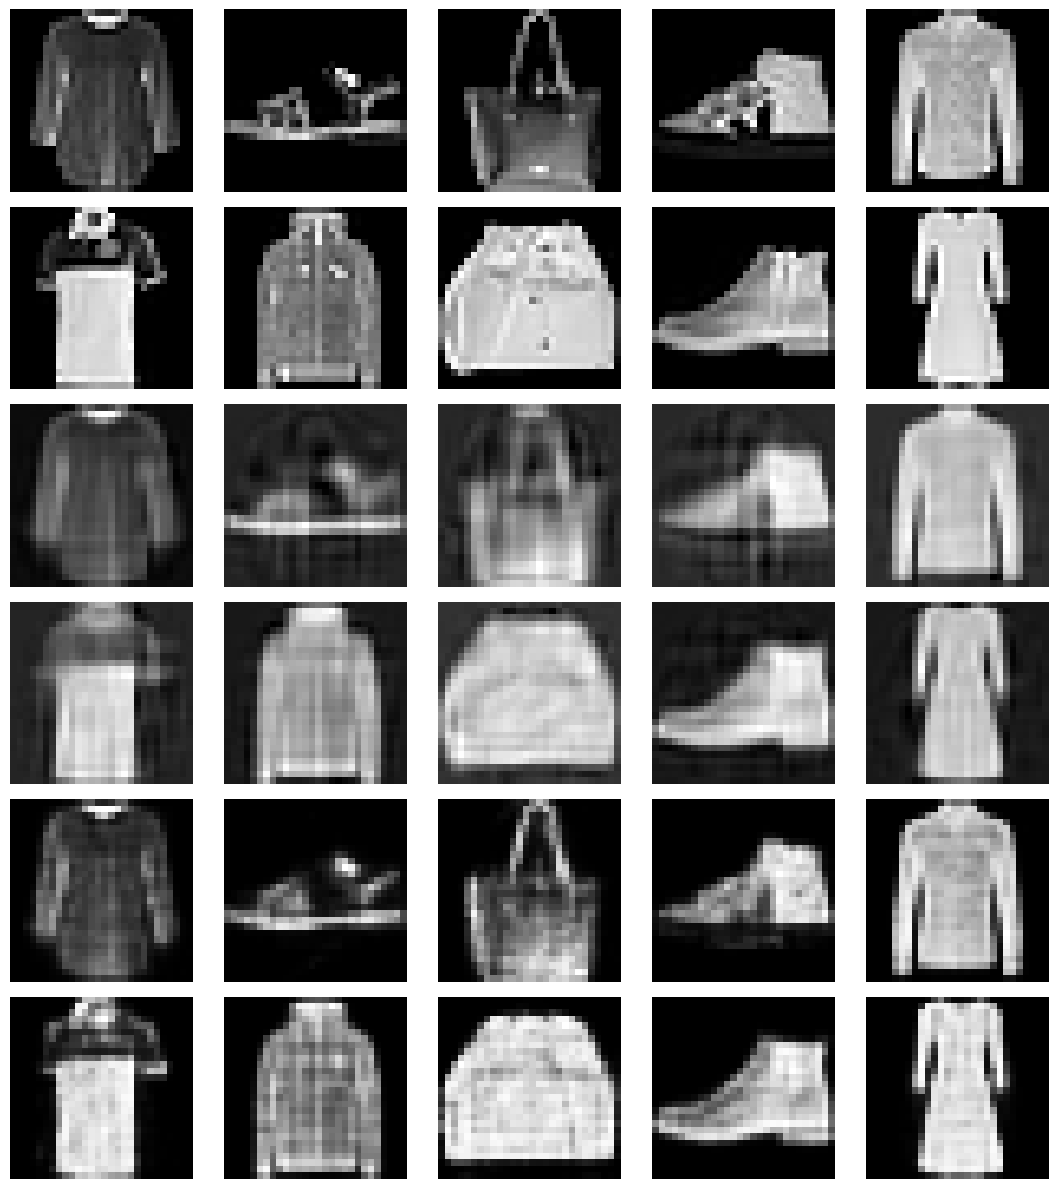

In [55]:
generator2= np.random.default_rng(60)
comparison_indxs2 = generator2.choice(len(X_validation_AE), size=10, replace=False)
original_images2 = X_validation_AE[comparison_indxs2]

nn_model_chosen.eval()
with torch.no_grad():
    comparison_AE = nn_model_chosen(original_images2)
original_images2 = original_images2.numpy()
comparison_AE = comparison_AE.numpy()

comparison_std = standardize(original_images2, means, devs)
comparison_Z = pca(comparison_std, pca_mean, autovectores, n_components_90)
comparison_PCA_std = reconstruction_pca(comparison_Z, pca_mean, autovectores, n_components_90)
comparison_PCA = comparison_PCA_std * devs + means

comparison = np.concatenate([original_images2, comparison_PCA, comparison_AE])
graph_images(comparison)

#### En las imágenes mostradas, podemos ver en las primeras 2 filas las imágenes originales, en la tercer y cuarta fila las reconstruidas con PCA y en la terquinta y sexta fila las imágenes del autoencoder. Es posible ver que ambos métodos, PCA y AE, mantienen la forma general de los objetos, sin embargo, las reconstrucciones del autoencoder presentan mayor definición en bordes y detalles. Las reconstrucciones de PCA tienen mayor suavizado y alteraciones en el fondo. 

In [57]:
mean_image = np.mean(original_images2, axis=0)
reference_error = np.sum((original_images2 - mean_image) ** 2)
PCA_error = np.sum((original_images2 - comparison_PCA) ** 2)
AE_error = np.sum((original_images2 - comparison_AE) ** 2)
r2_PCA = 1 - PCA_error / reference_error
r2_AE = 1 - AE_error / reference_error

print("PCA R²:", r2_PCA)
print("AE R²:", r2_AE)

PCA R²: 0.9022235806002821
AE R²: 0.9339694


#### Al comparar los errores R2 de ambos modelos sobre estas 10 imágenes, PCA obtuvo un valor de aproximadamente 0.902 y el autoencoder de 0.934. Por lo tanto, el autoencoder presentó una mejor reconstrucción de las imágenes ya que se acerca mas al valor de 1.  

#### e) Se obtuvieron las representaciones de menor dimensionalidad de los conjuntos de entrenamiento y evaluación utilizando las transformaciones previamente aprendidas por PCA y el encoder del AE. Cada imagen pasó de 784 características a 134 coordenadas latentes. Las representaciones se guardaron en nuevas variables para utilizarlas en los siguientes ejercicios.

In [61]:
PCA_train_latent = pca(X_train_std, pca_mean, autovectores, n_components_90)
PCA_test_latent = pca(X_test_std, pca_mean, autovectores, n_components_90)

nn_model_chosen.eval()
with torch.no_grad():
    AE_train_latent = nn_model_chosen.encoder(X_train_AE).numpy()
    AE_test_latent = nn_model_chosen.encoder(X_test_AE).numpy()

#### f ) Se implementó y entrenó un Autoencoder Variacional (VAE) utilizando Pytorch con una dimensión latente de 134 como se utilizó en PCA y AE. El encoder transforma los 784 valores de cada imágen mediante una capa intermedia de 300 neuronas y produce 134 medias y log-varianzas. A partir de ellas se puede muestrear un vector latente que el decoder utiliza para reconstruir la imágen. Se mantuvo la misma partición de entrenamiento, validación y prueba que se utilizó en el AE. Se empleó el optimizador Adam y un tamaño de batch de 115.

In [70]:
from src.var_autoencoder import Var_autoencoder, loss_VAE
X_fit_VAE = X_fit_AE.clone()
X_validation_VAE = X_validation_AE.clone()
X_test_VAE = X_test_AE.clone()
VAE_train_loader = DataLoader(X_fit_VAE, batch_size=115, shuffle=True)
VAE_validation_loader = DataLoader(X_validation_VAE, batch_size=115, shuffle=False)

def train_VAE(learning_rate, epochs):
    torch.manual_seed(60)
    VAE_model = Var_autoencoder(dim_final=n_components_90)
    VAE_optimizer = torch.optim.Adam(VAE_model.parameters(), lr=learning_rate)
    VAE_data = {
        "train_total": [],
        "train_reconstruction": [],
        "train_kl": [],
        "validation_total": [],
        "validation_reconstruction": [],
        "validation_kl": []
    }
    VAE_best_loss = float("inf")
    VAE_best_epoch = 0
    VAE_best_weights = None
    for epoch in range(epochs):
        VAE_model.train()
        total_train_loss = 0
        total_train_reconstruction = 0
        total_train_kl = 0
        for batch in VAE_train_loader:
            VAE_optimizer.zero_grad()
            reconstructed, mean, log_variance = VAE_model(batch)
            loss, reconstruction_loss, kl_loss = loss_VAE(batch, reconstructed, mean, log_variance)
            loss.backward()
            VAE_optimizer.step()
            total_train_loss += loss.item() * len(batch)
            total_train_reconstruction += reconstruction_loss.item() * len(batch)
            total_train_kl += kl_loss.item() * len(batch)
        VAE_data["train_total"].append(total_train_loss / len(X_fit_VAE))
        VAE_data["train_reconstruction"].append(total_train_reconstruction / len(X_fit_VAE))
        VAE_data["train_kl"].append(total_train_kl / len(X_fit_VAE))
        VAE_model.eval()
        total_validation_loss = 0
        total_validation_reconstruction = 0
        total_validation_kl = 0
        with torch.no_grad():
            for batch in VAE_validation_loader:
                reconstructed, mean, log_variance = VAE_model(batch)
                loss, reconstruction_loss, kl_loss = loss_VAE(batch, reconstructed, mean, log_variance)
                total_validation_loss += loss.item() * len(batch)
                total_validation_reconstruction += reconstruction_loss.item() * len(batch)
                total_validation_kl += kl_loss.item() * len(batch)
        validation_loss = total_validation_loss / len(X_validation_VAE)
        VAE_data["validation_total"].append(validation_loss)
        VAE_data["validation_reconstruction"].append(total_validation_reconstruction / len(X_validation_VAE))
        VAE_data["validation_kl"].append(total_validation_kl / len(X_validation_VAE))  
        if validation_loss < VAE_best_loss:
            VAE_best_loss = validation_loss
            VAE_best_epoch = epoch + 1
            VAE_best_weights = copy.deepcopy(VAE_model.state_dict())
    VAE_model.load_state_dict(VAE_best_weights)
    VAE_model.eval()
    return VAE_model, VAE_data, VAE_best_epoch, VAE_best_loss

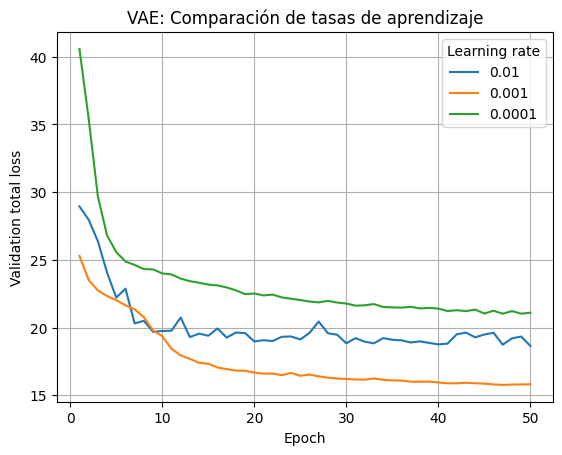

In [80]:
VAE_learning_rates = [0.01, 0.001, 0.0001]
VAE_results = {}
for learning_rate in VAE_learning_rates:
    VAE_model, VAE_data, VAE_best_epoch, VAE_best_loss = train_VAE(learning_rate, epochs=50)
    VAE_results[learning_rate] = {
        "model": VAE_model,
        "history": VAE_data,
        "best_epoch": VAE_best_epoch,
        "best_validation_loss": VAE_best_loss
    }

for learning_rate in VAE_results:
    history = VAE_results[learning_rate]["history"]
    epoch_numbers = range(1, len(history["validation_total"]) + 1)
    plt.plot(
        epoch_numbers,
        history["validation_total"],
        label=str(learning_rate)
    )
plt.xlabel("Epoch")
plt.ylabel("Validation total loss")
plt.title("VAE: Comparación de tasas de aprendizaje")
plt.legend(title="Learning rate")
plt.grid(True)
plt.show()

#### Se compararon tres tasas de aprendizaje utilizando la pérdida total de validación que incluye reconstrucción y KL. La tasa 0.001 obuvo el menor valor durante las 50 épocas evaluadas y se mostró mas estable que 0.01. Se seleccionó entonces esta tasa de aprendizaje para continuar el entrenamiento. 

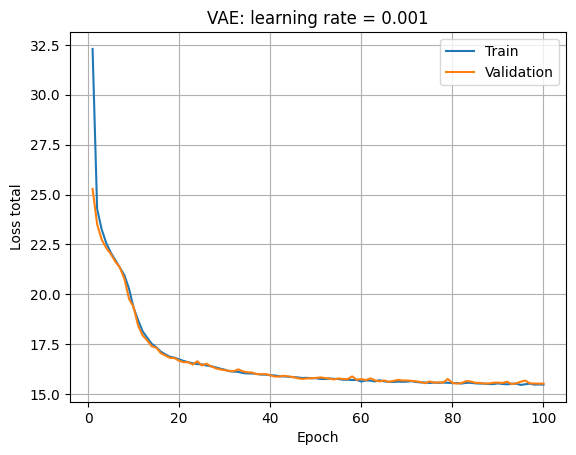

Best epoch: 93
Best validation loss: 15.507707357406616


In [75]:
VAE_model_100, VAE_data_100, VAE_best_epoch_100, VAE_best_loss_100 = (train_VAE(learning_rate=0.001, epochs=100))
VAE_epoch_numbers = range(1, len(VAE_data_100["train_total"]) + 1)
plt.plot(VAE_epoch_numbers, VAE_data_100["train_total"],label="Train")
plt.plot(VAE_epoch_numbers, VAE_data_100["validation_total"],label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss total")
plt.title("VAE: learning rate = 0.001")
plt.legend()
plt.grid(True)
plt.show()
print("Best epoch:", VAE_best_epoch_100)
print("Best validation loss:", VAE_best_loss_100)

#### Se amplió el entrenamiento a 100 épocas con una tasa de aprendizaje de 0.001. La pérdida total disminuye mucho al comienzo y luego presenta mejoras pequeñas. Las curvas de entrenamiento y validación son casi iguales sin evidencia de un aumento sostenido de la pérdida de validación. Se conservaron los pesos de la época con mejor pérdida que fue la época 93. 

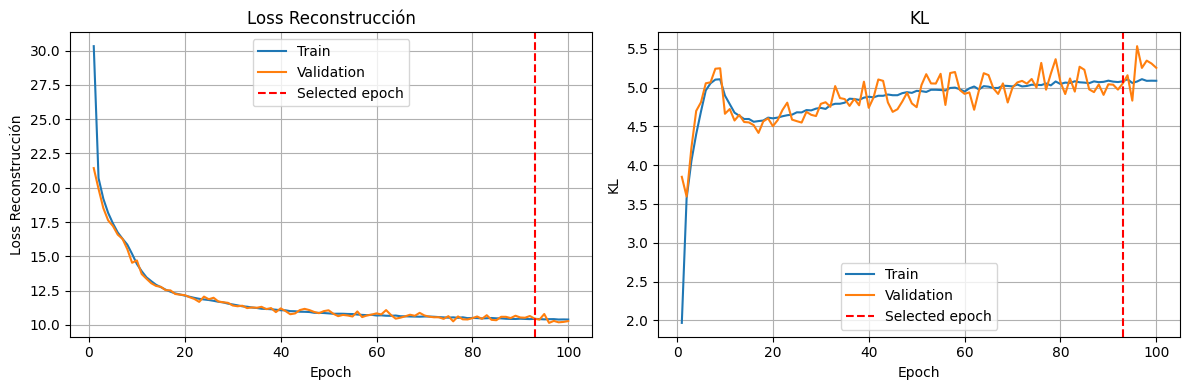

In [79]:
selected_index = VAE_best_epoch_100 - 1
reconstruction = VAE_data_100["validation_reconstruction"][selected_index]
kl = VAE_data_100["validation_kl"][selected_index]
VAE_epoch_numbers = range(1, len(VAE_data_100["train_total"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, term, title in zip(axes,["reconstruction", "kl"],["Loss Reconstrucción", "KL"]):
    ax.plot(VAE_epoch_numbers,VAE_data_100["train_" + term],label="Train")
    ax.plot(VAE_epoch_numbers,VAE_data_100["validation_" + term],label="Validation")
    ax.axvline(VAE_best_epoch_100, color="red",linestyle="--", label="Selected epoch")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.set_title(title)
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.show()

#### El VAE se entrena con una pérdida que combina dos partes. Por un lado, el error de reconstruccion compara los píxeles de cada imágen reconstruída con la original. Cuanto menor es, mas parecidas son. Por otro lado, KL mide cuánto se aleja la distribución latente que el encoder produce para cada imágen con una normal de referencia de media 0 y varianza 1. Al incluir KL en la pérdida, se penaliza ese alejamiento. Favorece que, después de entrenar, sea posible tomar vectores de la normal de referencia y pasarlos al decoder para generar imágenes. En el gráfico, podemos ver que la loss de reconstrucción baja mucho al comienzo, lo que significa que aprende rápido y luego las mejoras son menores. Mientras, en el gráfico de KL, la pérdida aumenta inicialmente  porque el encoder se aleja de la distribución de referencia mientras aprende a representar imágenes. El entrenamiento acepta ese aumento cuando la mejora en reconstrucción permite reducir la pérdida total. Luego, KL fluctúa alrededor de 5, mientras la recostrucción mejora cada vez menos. Eso sucede porque se está estabilizando la combinación de estos objetivos, aunque ninguno de los dos sea el valor ideal. 

#### Se compararon los tres modelos sobre las 10 imágenes utilizadas del conjunto de validación: 

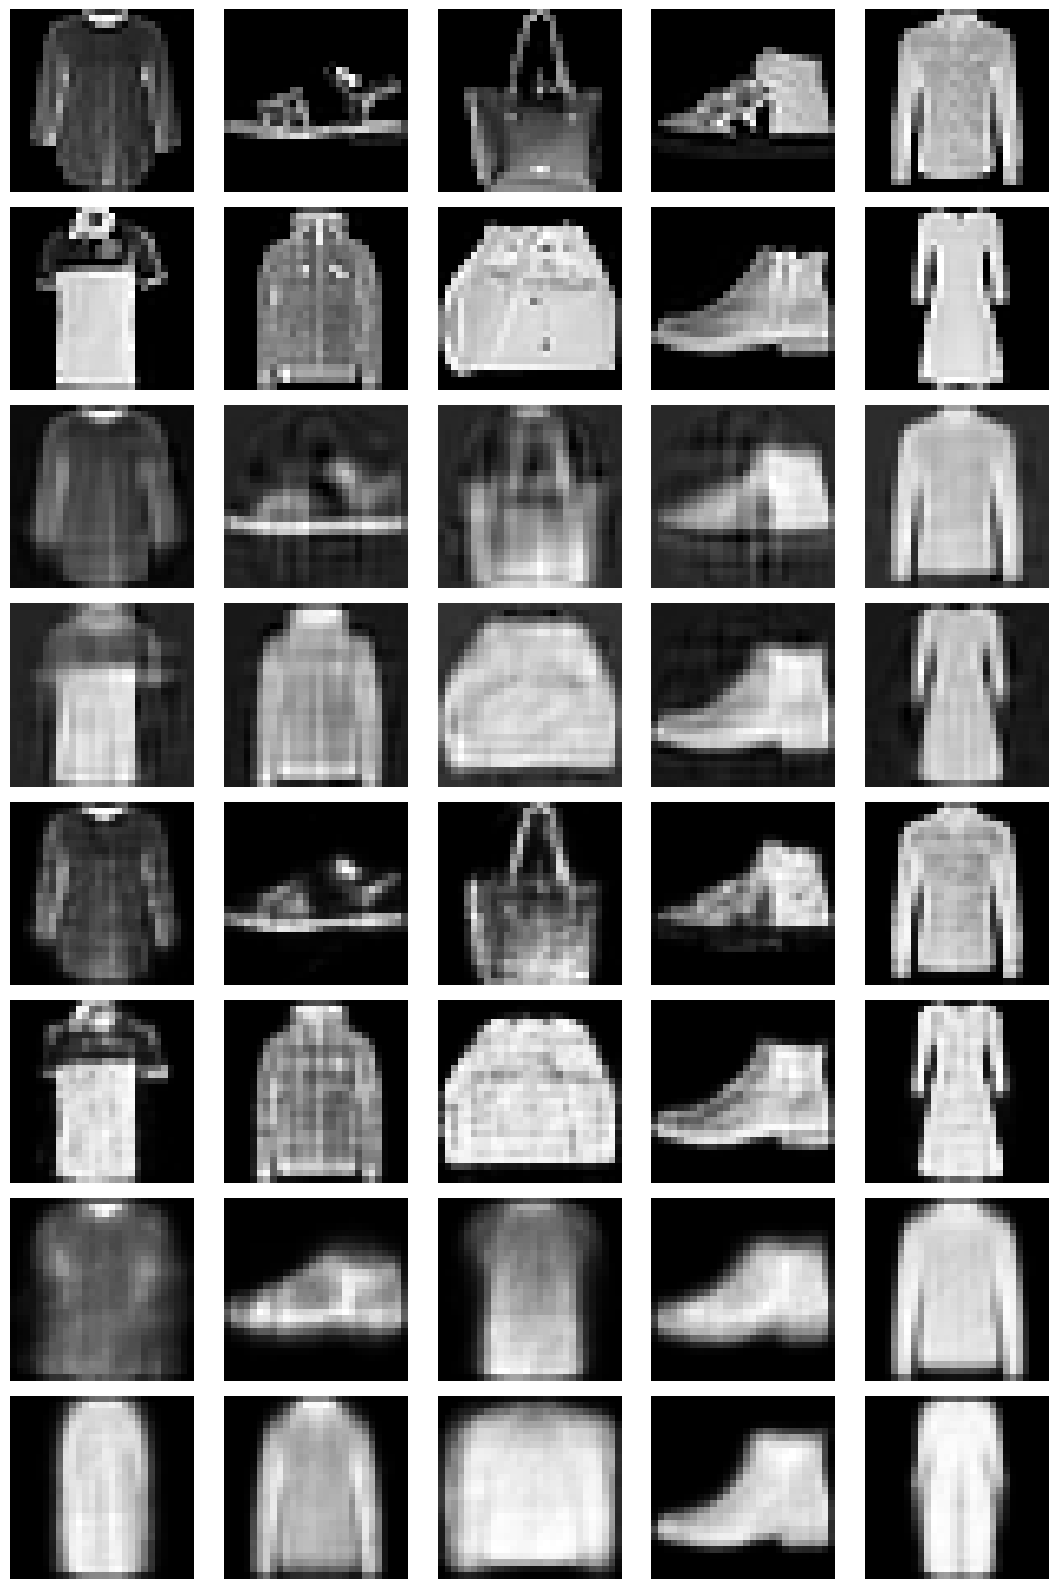

In [82]:
VAE_model_chosen = VAE_model_100
VAE_images = torch.tensor(original_images2, dtype=torch.float32)
VAE_model_chosen.eval()
with torch.no_grad():
    torch.manual_seed(60)
    comparison_VAE, mean, log_variance = VAE_model_chosen(VAE_images)
comparison_VAE = comparison_VAE.numpy()

comparison_all_models = np.concatenate([original_images2, comparison_PCA, comparison_AE, comparison_VAE])
graph_images(comparison_all_models)

#### Al comparar las imágenes reconstruidas por los tres métodos con las imágenes originales notamos que todos mantienen la estructura general de las imágenes, pero difieren mucho en los detalles. La fila tres y cuatro pertenecen a la reconstrucción de PCA, que se ve suavizada y sin límites definidos. Mientras, las filas 5 y 6 guardan las reconstrucciones del AE, que es el que mantiene el mayor nivel de detalle y definición. Finalmente, el VAE genera reconstrucciones borrosas y perde detalles. 

In [83]:
comparison_mean = np.mean(original_images2, axis=0)
reference_error = np.sum((original_images2 - comparison_mean) ** 2)
reconstructions = {
    "PCA": comparison_PCA,
    "AE": comparison_AE,
    "VAE": comparison_VAE
}
for name, reconstruction in reconstructions.items():
    reconstruction_error = np.sum(
        (original_images2 - reconstruction) ** 2
    )
    score = 1 - reconstruction_error / reference_error
    print(name, "R²:", score)

PCA R²: 0.9022235806002821
AE R²: 0.9339694
VAE R²: 0.63305736


#### Se calculó R2 de los tres modelos sobre estas 10 imágenes utilizando la imagen promedio como referencia común. El AE obtuvo el mayor resultado con aproximadamente 0.934, luego el PCA obtuvo 0.902 y el VAE uno mucho menor, de 0.633. Estos resultados coinciden con la comparación visual: el AE conserva mas detalle, el PCA menos pero mas que el VAE, y el VAE presenta mayor pérdida de información. Esto sucede porque el VAE no optimiza solamente la reconstrucción, tiene el objetivo añadido de regularización del espacio latente. 

1) Seleccionar el conjunto de entrenamiento y mostrar como se distribuyen las mues-
tras en AE vs en VAE en sus respectivos espacios latentes. Muestre las muestras
de distintas clases utilizando distintos colores en la representación. Para esta tarea
pueden aplicar PCA sobre el espacio latente y graficar las dos variables principales
más representativas.

Se visualizó como se distribuyen las imágenes del entrenamiento en AE y en VAE en sus espacios latentes respectivos. Se diferencian los colores de cada clase. Como los espacios tienen 134 dimensiones, se aplica PCA para poder representarlos en 2D. 


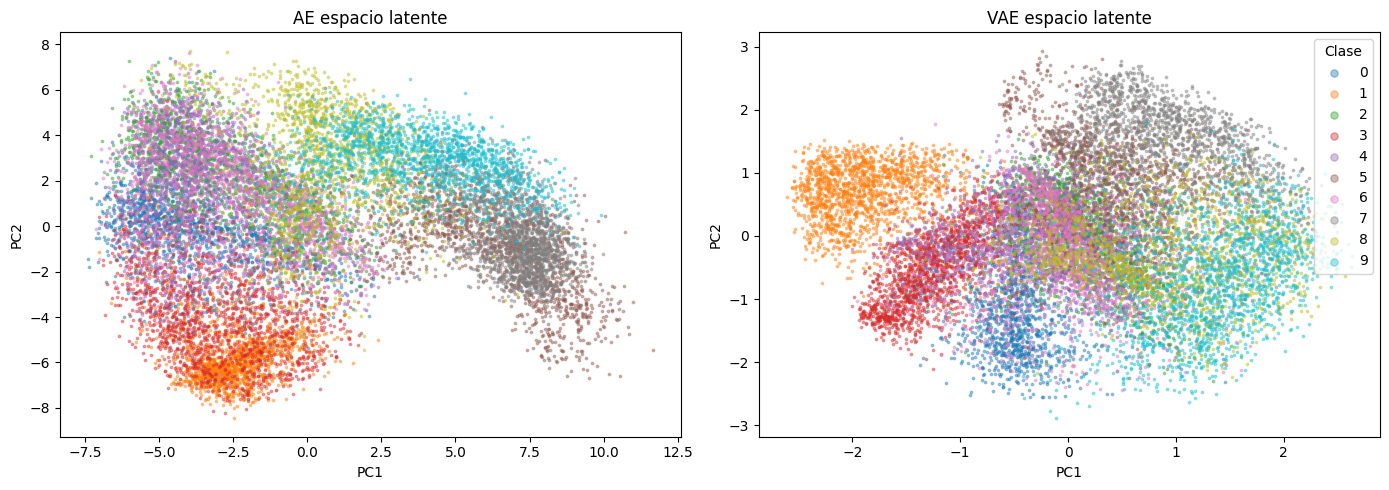

In [87]:
nn_model_chosen.eval()
VAE_model_chosen.eval()

with torch.no_grad():
    experiment1_AE_latent = nn_model_chosen.encoder(X_fit_AE).numpy()
    experiment1_VAE_mean, experiment1_VAE_log_variance = (VAE_model_chosen.encode(X_fit_VAE))
    experiment1_VAE_latent = experiment1_VAE_mean.numpy()
experiment1_labels = y_train[fit_indxs]

experiment1_AE_mean, _, experiment1_AE_vectors = pca_fit(experiment1_AE_latent)
experiment1_AE_2D = pca(experiment1_AE_latent, experiment1_AE_mean, experiment1_AE_vectors,2)
experiment1_VAE_mean_pca, _, experiment1_VAE_vectors = pca_fit(experiment1_VAE_latent)
experiment1_VAE_2D = pca(experiment1_VAE_latent, experiment1_VAE_mean_pca, experiment1_VAE_vectors, 2)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for class_label in range(10):
    selected = experiment1_labels == class_label
    color = plt.get_cmap("tab10")(class_label)
    axes[0].scatter(experiment1_AE_2D[selected, 0], experiment1_AE_2D[selected, 1], color=color, s=3, alpha=0.4, label=str(class_label))
    axes[1].scatter(experiment1_VAE_2D[selected, 0], experiment1_VAE_2D[selected, 1], color=color, s=3, alpha=0.4, label=str(class_label))
axes[0].set_title("AE espacio latente")
axes[1].set_title("VAE espacio latente")
for ax in axes:
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
axes[1].legend(title="Clase", markerscale=3)
plt.tight_layout()
plt.show()

#### En estos gráficos, se ven proyectados los espacios latentes de AE y VAE sobre sus dos primeras componentes principales. Cada fila o imágen se representa con 134 valores y luego convierte con PCA adaptado a cada uno de esos datos en un punto de 2D.  Cada imágen pertenece a unaa clase, indicada por su color. El VAE utiliza como puntos las medias encontradas por el encoder, que representan el centro de la distribución latente de cada imágen. Esta elección permite obtener una representación fija por imágen sin introducir variaciones por el muestreo aleatorio. Se puede decir que en ambos gráficos, las clases forman grupos relativamente distinguibles, sin embargo, varias presentan superposiciones. Al estar proyectando la información en 2 dimensiones, no podemos afirmar que esta separación o mezcla se mantenga en el espacio de 134 dimensiones. 

#### 2) Se seleccionaron 4 imágenes de la clase 1 del conjunto de validación. Para cada modelo, se obtuvo el embedding de cada imágen y se promediaron los cuatro vectores coordenada por coordenada. En el VAE, se utilizaron las medias del encoder como embeddings. Luego, cada decoder recibió el promedio de su modelo y produjo una nueva imágen, una versión que combina la representación de las cuatro referencias en lugar de reconstruír solo una de ellas. Se muestran las cuatro imágenes originales, y las creadas por cada modelo como promedio de las cuatro para analizar si conserva las característcas de la clase y si siguen siento reconocibles como pantalones las imágenes nuevas. 

Imágenes originales de la misma clase:


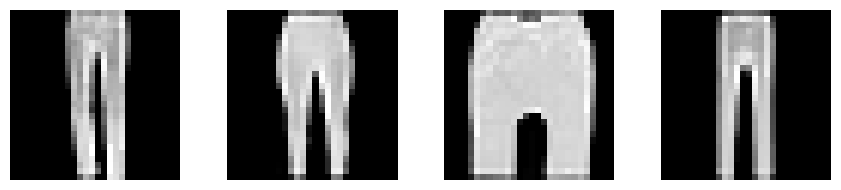

AE: imagen obtenida del embedding promedio


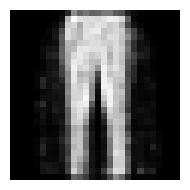

VAE: imagen obtenida del embedding promedio


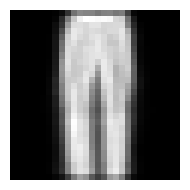

In [92]:
experiment2_generator = np.random.default_rng(60)
experiment2_labels = y_train[validation_indxs]
experiment2_class_indices = np.where(experiment2_labels == 1)[0]
experiment2_indices = experiment2_generator.choice(experiment2_class_indices, size=4, replace=False)
experiment2_images = X_validation_AE[experiment2_indices]

nn_model_chosen.eval()
VAE_model_chosen.eval()
with torch.no_grad():
    experiment2_AE_embeddings = nn_model_chosen.encoder(experiment2_images)
    experiment2_VAE_embeddings, _ = VAE_model_chosen.encode(experiment2_images)
    experiment2_AE_average = experiment2_AE_embeddings.mean(dim=0, keepdim=True)
    experiment2_VAE_average = experiment2_VAE_embeddings.mean(dim=0, keepdim=True)

with torch.no_grad():
    experiment2_AE_image = nn_model_chosen.decoder(experiment2_AE_average)
    experiment2_VAE_image = VAE_model_chosen.decode(experiment2_VAE_average)

print("Imágenes originales de la misma clase:")
graph_images(experiment2_images.numpy())
print("AE: imagen obtenida del embedding promedio")
graph_images(experiment2_AE_image.numpy())
print("VAE: imagen obtenida del embedding promedio")
graph_images(experiment2_VAE_image.numpy())


#### Al decodificar el promedio de los cuatro embeddings, es claro que estas modelos produjeron imágenes que mantienen la forma de pantalones, y entonces respetan las características de su clase. Se ve la cintura, la separación entre piernas. En el caso de AE, la imágen tiene mayor contraste y definición, mientras que el VAE presenta mayor suavidad y menos detalles. Por lo tanto, es claro que el promedio de las representaciones latentes conserva características de la clase. 

#### 3) Se generaron cinco vectores aleatorios de 134 valores cada uno. Cada valor se tomó de forma independiente de una distribución normal con media 0 y matriz de covarianza identidad. Se utilizaron estos vectores como entrada de los decoders ya entrenados de AE y VAE para producir imágenes sin partir de las originales. Se visualizaron las imágenes para comparar la capacidad de generación de los modelos a partir de esta distribución.  

Imágenes generadas desde N(0, I) con AE


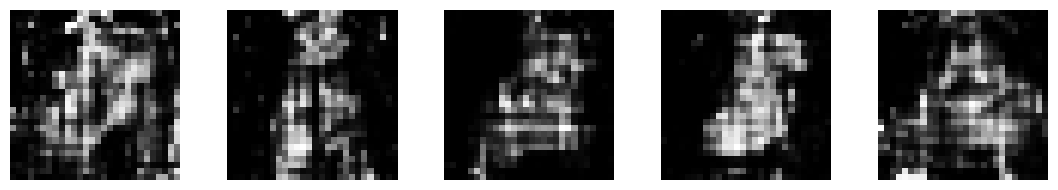

Imágenes generadas desde N(0, I) con VAE


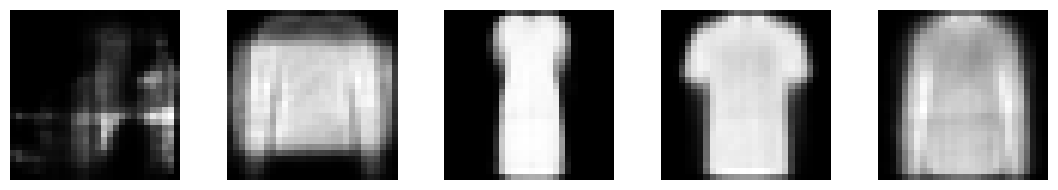

In [94]:
torch.manual_seed(60)
experiment3_vectors = torch.randn(5, n_components_90)
nn_model_chosen.eval()
VAE_model_chosen.eval()
with torch.no_grad():
    experiment3_AE_images = nn_model_chosen.decoder(experiment3_vectors)
    experiment3_VAE_images = VAE_model_chosen.decode(experiment3_vectors)
print("Imágenes generadas desde N(0, I) con AE")
graph_images(experiment3_AE_images.numpy())
print("Imágenes generadas desde N(0, I) con VAE")
graph_images(experiment3_VAE_images.numpy())

#### Al decodificar los cinco vetores muestreados podemos notar una gran diferencia entre las imágenes que generaron estos modelos. El AE produjo imágenes con patrones fragmentados y formas irreconocibles. Mientras, el VAE genera formas mucho mas reconocibles que el AE, aunque siguen siendo borrosas y sin detalle. Esta diferencia está relacionada con el entrenamiento del VAE que incluye la penalización para acercar las distribuciones de sus códigos a la normal utilizada en este experimento. En cambio, el AE no tiene esta condición por lo que no fue entrenado para que sus códigos sigan esa distribución. Por eso, en estas cinco imágenes, VAE fue capaz de producir imágenes mas reconocibles que el AE al recibir vectores con esta distribución. 

### Parte 3: Clustering